## Setup & imports (version pins)

In [ ]:
!pip install -q --force-reinstall "albumentations==1.4.15" "albucore==0.0.16"
!pip install -q transformers==4.44.2 opencv-python-headless==4.10.0.84 timm==1.0.9

In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [2]:
import os, json, time, random, math, copy
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import matplotlib.pyplot as plt
from transformers import Dinov2Model, Dinov2Config

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| torch:", torch.__version__, "| transformers OK")

Device: cuda | torch: 2.10.0+cu128 | transformers OK


## Master config cell

In [3]:
CONFIG = {
    "nb0_dataset_slug": "/kaggle/input/datasets/afrinaalam/nb0-artifacts",       # Kaggle dataset with nb0_artifacts/
    "dataprep_dir_slug": "/kaggle/input/datasets/afrinaalam/partb-outputs",     # Kaggle dataset with partb_dataprep_artifacts/
    "raw_dataset_slug": "/kaggle/input/datasets/afrinaalam/foodbd2",         # try this first; else your own uploaded copy
    # -------------------------------------------------------------

    "out_dir": "/kaggle/working/dinov2_outputs",

    "hf_backbone": "facebook/dinov2-small",
    "patch_size": 14,
    "encoder_img_size": 518,                  # 37*14 -- Part-A used 512, forced up for patch_size=14
    "layer_taps": [2, 5, 8, 11],

    "ssl_epochs": 50,
    "global_crop_size": 518,
    "local_crop_size": 224,
    "n_global_crops": 2,
    "n_local_crops": 2,
    "global_scale": (0.4, 1.0),
    "local_scale": (0.05, 0.4),
    "ssl_batch_size": 6,
    "ssl_base_lr": 5e-4,
    "ssl_min_lr": 1e-6,
    "ssl_warmup_epochs": 10,
    "ssl_weight_decay": (0.04, 0.4),
    "ssl_momentum_teacher": (0.996, 1.0),
    "teacher_temp": (0.04, 0.07),
    "teacher_temp_warmup_epochs": 30,
    "student_temp": 0.1,
    "head_hidden_dim": 2048,
    "head_bottleneck_dim": 256,
    "head_out_dim": 4096,
    "freeze_last_layer_epochs": 1,
    "clip_grad": 3.0,
    "center_momentum": 0.9,

    "decoder_embed_dim": 256,
    "ft_epochs": 50,
    "ft_batch_size": 8,
    "ft_lr_encoder": 1e-5,
    "ft_lr_decoder": 1e-4,
    "ft_weight_decay": 1e-4,
    "encoder_mode": "finetune",

    "seed": SEED,
}
os.makedirs(CONFIG["out_dir"], exist_ok=True)
print(json.dumps(CONFIG, indent=2, default=str))

{
  "nb0_dataset_slug": "/kaggle/input/datasets/afrinaalam/nb0-artifacts",
  "dataprep_dir_slug": "/kaggle/input/datasets/afrinaalam/partb-outputs",
  "raw_dataset_slug": "/kaggle/input/datasets/afrinaalam/foodbd2",
  "out_dir": "/kaggle/working/dinov2_outputs",
  "hf_backbone": "facebook/dinov2-small",
  "patch_size": 14,
  "encoder_img_size": 518,
  "layer_taps": [
    2,
    5,
    8,
    11
  ],
  "ssl_epochs": 50,
  "global_crop_size": 518,
  "local_crop_size": 224,
  "n_global_crops": 2,
  "n_local_crops": 2,
  "global_scale": [
    0.4,
    1.0
  ],
  "local_scale": [
    0.05,
    0.4
  ],
  "ssl_batch_size": 6,
  "ssl_base_lr": 0.0005,
  "ssl_min_lr": 1e-06,
  "ssl_warmup_epochs": 10,
  "ssl_weight_decay": [
    0.04,
    0.4
  ],
  "ssl_momentum_teacher": [
    0.996,
    1.0
  ],
  "teacher_temp": [
    0.04,
    0.07
  ],
  "teacher_temp_warmup_epochs": 30,
  "student_temp": 0.1,
  "head_hidden_dim": 2048,
  "head_bottleneck_dim": 256,
  "head_out_dim": 4096,
  "freeze_last

## Load Task‑A split roles

In [5]:
import sys

def _resolve(slug):
    return slug if slug.startswith("/") else f"/kaggle/input/{slug}"

# --- NB0 artifacts (your real seg_common.py) ---
NB0_DIR = _resolve(CONFIG["nb0_dataset_slug"])
assert os.path.exists(f"{NB0_DIR}/common_config.json"), (
    f"common_config.json not found under {NB0_DIR}. "
    f"Run `!ls -R /kaggle/input` and fix CONFIG['nb0_dataset_slug']."
)
sys.path.insert(0, NB0_DIR)
from seg_common import load_common_config, load_split_manifest, polygons_to_mask, get_transforms, FoodSegDataset

cfg = load_common_config(f"{NB0_DIR}/common_config.json")
IMG_SIZE_PARTA = cfg["img_size"]                        # 512, Part-A's resolution (reference only)
NUM_CLASSES = cfg["num_classes_total"]                  # 68 (67 food classes + background)
CLASS_NAMES = ["background"] + cfg["class_names"]
CONFIG["num_classes"] = NUM_CLASSES
print(f"NUM_CLASSES={NUM_CLASSES} | Part-A IMG_SIZE={IMG_SIZE_PARTA} | DINOv2 encoder IMG_SIZE={CONFIG['encoder_img_size']}")

# --- Part-B role-mapped split (Task A, already done) ---
DATAPREP_DIR = _resolve(CONFIG["dataprep_dir_slug"])
sys.path.insert(0, DATAPREP_DIR)
from ssl_common import load_partb_config, load_remapped_split

partb_cfg = load_partb_config(f"{DATAPREP_DIR}/partb_config.json")
splits = load_remapped_split(f"{DATAPREP_DIR}/split_manifest_remapped.json")

# --- point paths at whichever raw-dataset copy you actually attached ---
BAKED_ROOT = cfg["data_root"]                            # what NB0 recorded when it ran
RAW_ROOT = f"{_resolve(CONFIG['raw_dataset_slug'])}/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD"

def _remap(p):
    return p.replace(BAKED_ROOT, RAW_ROOT) if isinstance(p, str) else p

for key in ["train", "valid", "test"]:
    splits[key] = [_remap(p) for p in splits[key]]

train_imgs = splits["train"]   # 2473 -> unlabelled SSL pretraining corpus (Task B)
valid_imgs = splits["valid"]   # 697  -> labelled fine-tuning set (Task D)
test_imgs  = splits["test"]    # 353  -> downstream monitoring + final eval (Task D & E, double role)

_missing = [p for p in (train_imgs[:3] + valid_imgs[:3] + test_imgs[:3]) if not os.path.exists(p)]
if _missing:
    print("RAW DATASET NOT FOUND at:")
    for p in _missing: print("  ", p)
    print("\nMounted under /kaggle/input:")
    for root, dirs, files in os.walk("/kaggle/input"):
        if files: print("  ", root, "->", len(files), "files, e.g.", files[0])
    raise FileNotFoundError("Attach the raw FoodBD dataset, or fix CONFIG['raw_dataset_slug'].")
print(f"Paths resolve OK. train={len(train_imgs)} valid={len(valid_imgs)} test={len(test_imgs)}")

# sanity: a label file should exist next to the first train image
sample_label = train_imgs[0].replace("/images/", "/labels/").rsplit(".",1)[0] + ".txt"
print("Sample label file exists:", os.path.exists(sample_label), "->", sample_label)

NUM_CLASSES=68 | Part-A IMG_SIZE=512 | DINOv2 encoder IMG_SIZE=518
Paths resolve OK. train=2473 valid=697 test=353
Sample label file exists: True -> /kaggle/input/datasets/afrinaalam/foodbd2/FoodBD A Polygon-Annotated Meal Image Dataset of B/root/FoodBD/train/labels/FoodBD-0002.txt


## Transforms (reuse Part‑A's get_transforms, just at 518px for the encoder)

In [6]:
# SSL multi-crop augmentation (Task B, images only) -- DINOv2-specific, no equivalent in seg_common
global_tf = A.Compose([
    A.RandomResizedCrop(size=(CONFIG["global_crop_size"], CONFIG["global_crop_size"]),
                         scale=CONFIG["global_scale"], ratio=(0.75, 1.33)),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(0.4, 0.4, 0.2, 0.1, p=0.8),
    A.ToGray(p=0.2),
    A.GaussianBlur(blur_limit=(3, 7), p=0.5),
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
    ToTensorV2(),
])
local_tf = A.Compose([
    A.RandomResizedCrop(size=(CONFIG["local_crop_size"], CONFIG["local_crop_size"]),
                         scale=CONFIG["local_scale"], ratio=(0.75, 1.33)),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(0.4, 0.4, 0.2, 0.1, p=0.8),
    A.ToGray(p=0.2),
    A.GaussianBlur(blur_limit=(3, 7), p=0.5),
    A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)),
    ToTensorV2(),
])

# Task D/E: identical synced image+mask pipeline as Part-A, just resized to the encoder's
# patch-14-compatible resolution (518) instead of Part-A's 512 -- this is the Task C adapter.
IMG_SIZE = CONFIG["encoder_img_size"]
finetune_tf = get_transforms(IMG_SIZE, train=True)    # labelled fine-tune (valid split)
eval_tf     = get_transforms(IMG_SIZE, train=False)   # deterministic (test split)

/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/kaggle/input/datasets/afrinaalam/nb0-artifacts/seg_common.py:40: UserWarning: Argument(s) 'value, mask_value' are not valid for transform ShiftScaleRotate
  A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.15, rotate_limit=15, p=0.5,
/kaggle/input/datasets/afrinaalam/nb0-artifacts/seg_common.py:45: UserWarning: Argument(s) 'max_holes, max_height, max_width, fill_value, mask_fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=4, max_height=32, max_width=32, fill_value=0, mask_fill_value=0, p=0.2),


## Datasets (FoodSegDataset for labelled data, custom loader for unlabelled)

In [7]:
class MultiCropDINODataset(Dataset):
    """Task B: images-only, no masks -- FoodSegDataset isn't needed (and would waste time
    rasterizing polygons for 2473 images x 50 epochs with no benefit)."""
    def __init__(self, img_paths, global_tf, local_tf, n_global=2, n_local=4):
        self.img_paths = img_paths
        self.global_tf, self.local_tf = global_tf, local_tf
        self.n_global, self.n_local = n_global, n_local

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img = cv2.cvtColor(cv2.imread(str(self.img_paths[idx])), cv2.COLOR_BGR2RGB)
        crops = [self.global_tf(image=img)["image"] for _ in range(self.n_global)]
        crops += [self.local_tf(image=img)["image"] for _ in range(self.n_local)]
        return crops

def multicrop_collate(batch):
    n_views = len(batch[0])
    return [torch.stack([sample[v] for sample in batch]) for v in range(n_views)]

ssl_ds  = MultiCropDINODataset(train_imgs, global_tf, local_tf,
                                CONFIG["n_global_crops"], CONFIG["n_local_crops"])

# Task D & E: reuse Part-A's exact FoodSegDataset (polygon->mask logic), same bg_is_zero flag
ft_ds   = FoodSegDataset(valid_imgs, finetune_tf, bg_is_zero=cfg["bg_is_zero"])
test_ds = FoodSegDataset(test_imgs,  eval_tf,     bg_is_zero=cfg["bg_is_zero"])

ssl_loader  = DataLoader(ssl_ds, batch_size=CONFIG["ssl_batch_size"], shuffle=True,
                          num_workers=4, pin_memory=True, drop_last=True, collate_fn=multicrop_collate)
ft_loader   = DataLoader(ft_ds, batch_size=CONFIG["ft_batch_size"], shuffle=True,
                          num_workers=4, pin_memory=True, drop_last=True)
test_loader = DataLoader(test_ds, batch_size=CONFIG["ft_batch_size"], shuffle=False,
                          num_workers=4, pin_memory=True)

print(f"SSL batches/epoch: {len(ssl_loader)} | FT batches/epoch: {len(ft_loader)} | Test batches: {len(test_loader)}")

SSL batches/epoch: 412 | FT batches/epoch: 87 | Test batches: 45


## Sanity checks

In [8]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

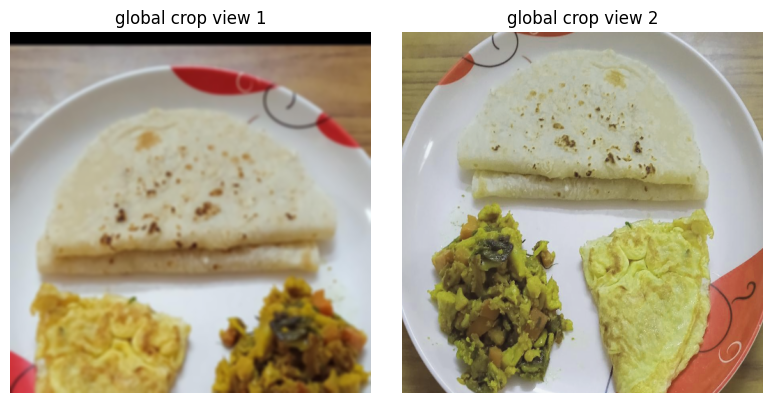

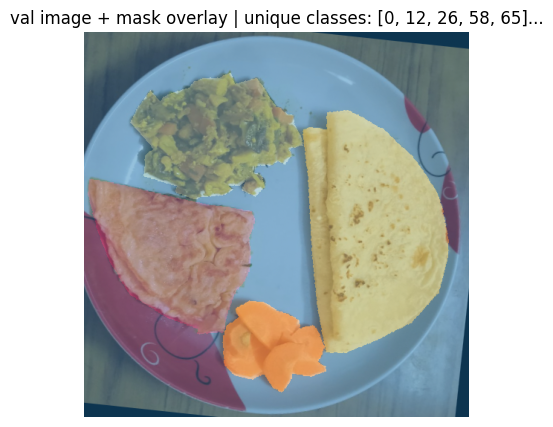

In [9]:
def denorm(t):
    m = np.array(IMAGENET_MEAN).reshape(3,1,1); s = np.array(IMAGENET_STD).reshape(3,1,1)
    x = t.numpy() * s + m
    return np.clip(x.transpose(1,2,0), 0, 1)

# (a) two augmented views of the same unlabelled train image
sample_views = ssl_ds[0]
fig, axes = plt.subplots(1, 2, figsize=(8,4))
axes[0].imshow(denorm(sample_views[0])); axes[0].set_title("global crop view 1"); axes[0].axis("off")
axes[1].imshow(denorm(sample_views[1])); axes[1].set_title("global crop view 2"); axes[1].axis("off")
plt.tight_layout(); plt.show()

# (b) validation-split image with mask overlay -- CHECK THIS LOOKS RIGHT before trusting derive_mask_path()
img_t, mask_t = ft_ds[0]
img_np = denorm(img_t)
fig, ax = plt.subplots(1,1, figsize=(5,5))
ax.imshow(img_np)
ax.imshow(mask_t.numpy(), alpha=0.45, cmap="tab20")
ax.set_title(f"val image + mask overlay | unique classes: {torch.unique(mask_t).tolist()[:10]}...")
ax.axis("off")
plt.show()

## DINOv2 backbone + Task‑C adapter (token→2D‑grid reshape)

In [10]:
def build_dinov2_backbone(name=CONFIG["hf_backbone"]):
    model = Dinov2Model.from_pretrained(name)
    return model

def get_multilevel_tokens(backbone, pixel_values, layer_idxs, patch_size):
    """
    Task C adapter: DINOv2 is a *non-hierarchical* ViT (all patches share one resolution),
    unlike SegFormer's MiT encoder (4 genuinely multi-scale stages). To still feed a
    4-input SegFormer-style All-MLP head, we tap 4 different transformer DEPTHS instead
    of 4 different spatial SCALES, all at the same (H/14, W/14) resolution. Because all
    4 taps are already the same resolution, no per-level upsampling is needed before
    concatenation (SegFormer's head upsamples c1..c4 to a common size first — that step
    becomes a no-op adapter here, but is kept explicit for clarity).
    """
    B, C, H, W = pixel_values.shape
    Hp, Wp = H // patch_size, W // patch_size
    out = backbone(pixel_values=pixel_values, output_hidden_states=True,
                    interpolate_pos_encoding=True)
    hidden_states = out.hidden_states  # tuple: [embeddings, layer1, layer2, ..., layerN]

    maps = []
    for idx in layer_idxs:
        tokens = hidden_states[idx + 1]        # +1 to skip the embedding-output entry
        tokens = tokens[:, 1:, :]               # drop CLS token, keep patch tokens
        fmap = tokens.transpose(1, 2).reshape(B, -1, Hp, Wp)  # (B, C, Hp, Wp) adapter reshape
        maps.append(fmap)
    return maps  # list of 4 tensors, each (B, embed_dim_backbone, Hp, Wp)

## DINO projection head, multi-crop wrapper, DINO loss

In [12]:
class DINOHead(nn.Module):
    def __init__(self, in_dim, hidden_dim, bottleneck_dim, out_dim):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim), nn.GELU(),
            nn.Linear(hidden_dim, bottleneck_dim),
        )
        self.last_layer = nn.utils.weight_norm(nn.Linear(bottleneck_dim, out_dim, bias=False))
        self.last_layer.weight_g.data.fill_(1.0)
        self.last_layer.weight_g.requires_grad = False

    def forward(self, x):
        x = self.mlp(x)
        x = F.normalize(x, dim=-1, p=2)
        return self.last_layer(x)


class MultiCropWrapper(nn.Module):
    """Groups same-resolution crops into single forward passes through the backbone."""
    def __init__(self, backbone, head):
        super().__init__()
        self.backbone, self.head = backbone, head

    def forward(self, crops):
        sizes = torch.tensor([c.shape[-1] for c in crops])
        unique_sizes, counts = torch.unique_consecutive(sizes, return_counts=True)
        idx_crops = torch.cumsum(counts, 0)
        start, outputs = 0, []
        for end in idx_crops:
            chunk = torch.cat(crops[start:end], dim=0)
            cls_tok = self.backbone(pixel_values=chunk, interpolate_pos_encoding=True).last_hidden_state[:, 0]
            outputs.append(cls_tok)
            start = end
        cat = torch.cat(outputs, dim=0)
        return self.head(cat)


class DINOLoss(nn.Module):
    def __init__(self, out_dim, n_global, n_local, student_temp, teacher_temp_sched, center_momentum):
        super().__init__()
        self.n_global, self.n_local = n_global, n_local
        self.student_temp = student_temp
        self.teacher_temp_sched = teacher_temp_sched
        self.center_momentum = center_momentum
        self.register_buffer("center", torch.zeros(1, out_dim))

    def forward(self, student_out, teacher_out, epoch):
        student_out = student_out / self.student_temp
        student_chunks = student_out.chunk(self.n_global + self.n_local)

        teacher_temp = self.teacher_temp_sched[epoch]
        teacher_out = F.softmax((teacher_out - self.center) / teacher_temp, dim=-1).detach()
        teacher_chunks = teacher_out.chunk(self.n_global)

        total_loss, n_terms = 0.0, 0
        for t_idx, t in enumerate(teacher_chunks):
            for s_idx, s in enumerate(student_chunks):
                if s_idx == t_idx and s_idx < self.n_global:
                    continue  # skip matching global view with itself
                loss = torch.sum(-t * F.log_softmax(s, dim=-1), dim=-1).mean()
                total_loss += loss
                n_terms += 1
        self.update_center(teacher_out)
        return total_loss / n_terms

    @torch.no_grad()
    def update_center(self, teacher_out):
        batch_center = teacher_out.mean(dim=0, keepdim=True)
        self.center = self.center * self.center_momentum + batch_center * (1 - self.center_momentum)

## Build student/teacher, schedules, optimizer

In [13]:
def cosine_schedule(base, final, epochs, warmup_epochs=0, warmup_start=0.0):
    warmup = np.linspace(warmup_start, base, warmup_epochs)
    remain = epochs - warmup_epochs
    t = np.arange(remain)
    cosine = final + 0.5 * (base - final) * (1 + np.cos(np.pi * t / remain))
    return np.concatenate([warmup, cosine])

EP = CONFIG["ssl_epochs"]
lr_sched  = cosine_schedule(CONFIG["ssl_base_lr"] * CONFIG["ssl_batch_size"] / 256,
                             CONFIG["ssl_min_lr"], EP, CONFIG["ssl_warmup_epochs"])
wd_sched  = cosine_schedule(CONFIG["ssl_weight_decay"][1], CONFIG["ssl_weight_decay"][0], EP)[::-1]
mom_sched = cosine_schedule(CONFIG["ssl_momentum_teacher"][1], CONFIG["ssl_momentum_teacher"][0], EP)[::-1]
teacher_temp_sched = np.concatenate([
    np.linspace(CONFIG["teacher_temp"][0], CONFIG["teacher_temp"][1], CONFIG["teacher_temp_warmup_epochs"]),
    np.full(EP - CONFIG["teacher_temp_warmup_epochs"], CONFIG["teacher_temp"][1]),
])

student_backbone = build_dinov2_backbone().to(DEVICE)
teacher_backbone = build_dinov2_backbone().to(DEVICE)
embed_dim = student_backbone.config.hidden_size

student_head = DINOHead(embed_dim, CONFIG["head_hidden_dim"], CONFIG["head_bottleneck_dim"], CONFIG["head_out_dim"])
teacher_head = DINOHead(embed_dim, CONFIG["head_hidden_dim"], CONFIG["head_bottleneck_dim"], CONFIG["head_out_dim"])

student = MultiCropWrapper(student_backbone, student_head).to(DEVICE)
teacher = MultiCropWrapper(teacher_backbone, teacher_head).to(DEVICE)
teacher.load_state_dict(student.state_dict())
for p in teacher.parameters():
    p.requires_grad = False

dino_loss = DINOLoss(CONFIG["head_out_dim"], CONFIG["n_global_crops"], CONFIG["n_local_crops"],
                      CONFIG["student_temp"], teacher_temp_sched, CONFIG["center_momentum"]).to(DEVICE)

optimizer = torch.optim.AdamW(student.parameters(), lr=lr_sched[0])
scaler = torch.cuda.amp.GradScaler()

print(f"Backbone: {CONFIG['hf_backbone']} | embed_dim={embed_dim} | params(student)={sum(p.numel() for p in student.parameters())/1e6:.1f}M")

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Backbone: facebook/dinov2-small | embed_dim=384 | params(student)=28.6M


/usr/local/lib/python3.12/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
/tmp/ipykernel_58/4089745167.py:35: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


## Task B: SSL pretraining loop (50 epochs, timed, checkpointed)

/tmp/ipykernel_58/3760045805.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


[SSL] epoch 1/50 | loss=7.7280 | 238.5s/epoch
[SSL] epoch 2/50 | loss=6.8016 | 248.1s/epoch
[SSL] epoch 3/50 | loss=3.0134 | 249.1s/epoch
[SSL] epoch 4/50 | loss=1.1330 | 248.8s/epoch
[SSL] epoch 5/50 | loss=0.8885 | 246.3s/epoch
[SSL] epoch 6/50 | loss=0.7942 | 247.8s/epoch
[SSL] epoch 7/50 | loss=0.6944 | 245.5s/epoch
[SSL] epoch 8/50 | loss=0.6124 | 245.1s/epoch
[SSL] epoch 9/50 | loss=0.5364 | 245.2s/epoch
[SSL] epoch 10/50 | loss=0.4420 | 243.6s/epoch
[SSL] epoch 11/50 | loss=0.3946 | 243.2s/epoch
[SSL] epoch 12/50 | loss=0.3421 | 244.3s/epoch
[SSL] epoch 13/50 | loss=0.3261 | 242.5s/epoch
[SSL] epoch 14/50 | loss=0.2920 | 242.0s/epoch
[SSL] epoch 15/50 | loss=0.2800 | 242.1s/epoch
[SSL] epoch 16/50 | loss=0.2502 | 241.7s/epoch
[SSL] epoch 17/50 | loss=0.2446 | 241.1s/epoch
[SSL] epoch 18/50 | loss=0.2377 | 241.0s/epoch
[SSL] epoch 19/50 | loss=0.2210 | 240.4s/epoch
[SSL] epoch 20/50 | loss=0.2025 | 240.8s/epoch
[SSL] epoch 21/50 | loss=0.2145 | 240.3s/epoch
[SSL] epoch 22/50 | lo

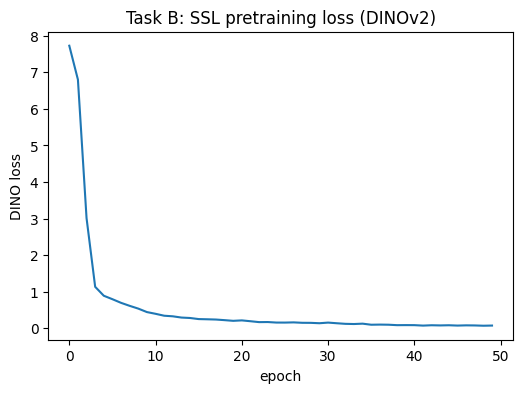

In [14]:
os.makedirs(f"{CONFIG['out_dir']}/ssl_ckpts", exist_ok=True)
ssl_loss_history, ssl_epoch_times = [], []

for epoch in range(CONFIG["ssl_epochs"]):
    t0 = time.time()
    for g in optimizer.param_groups:
        g["lr"] = lr_sched[epoch]
        g["weight_decay"] = wd_sched[epoch]

    student.train()
    running_loss, n_batches = 0.0, 0
    for crops in ssl_loader:
        crops = [c.to(DEVICE, non_blocking=True) for c in crops]

        with torch.cuda.amp.autocast():
            student_out = student(crops)
            with torch.no_grad():
                teacher_out = teacher(crops[:CONFIG["n_global_crops"]])
            loss = dino_loss(student_out, teacher_out, epoch)

        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(student.parameters(), CONFIG["clip_grad"])
        if epoch < CONFIG["freeze_last_layer_epochs"]:
            for n, p in student.head.named_parameters():
                if "last_layer" in n:
                    p.grad = None
        scaler.step(optimizer)
        scaler.update()

        with torch.no_grad():
            m = mom_sched[epoch]
            for ps, pt in zip(student.parameters(), teacher.parameters()):
                pt.data.mul_(m).add_((1 - m) * ps.detach().data)

        running_loss += loss.item(); n_batches += 1

    epoch_loss = running_loss / n_batches
    epoch_time = time.time() - t0
    ssl_loss_history.append(epoch_loss)
    ssl_epoch_times.append(epoch_time)
    print(f"[SSL] epoch {epoch+1}/{CONFIG['ssl_epochs']} | loss={epoch_loss:.4f} | {epoch_time:.1f}s/epoch")

    if (epoch + 1) % 10 == 0 or epoch == CONFIG["ssl_epochs"] - 1:
        torch.save(student_backbone.state_dict(), f"{CONFIG['out_dir']}/ssl_ckpts/dinov2_student_ep{epoch+1}.pth")

print(f"Avg per-epoch SSL time: {np.mean(ssl_epoch_times):.1f}s "
      f"({'>10min -> consider splitting into pretrain/downstream notebooks' if np.mean(ssl_epoch_times) > 600 else 'OK within a single notebook'})")

plt.figure(figsize=(6,4))
plt.plot(ssl_loss_history)
plt.xlabel("epoch"); plt.ylabel("DINO loss"); plt.title("Task B: SSL pretraining loss (DINOv2)")
plt.savefig(f"{CONFIG['out_dir']}/dinov2_ssl_loss_curve.png", dpi=150); plt.show()

# use the SSL-pretrained student backbone going forward
pretrained_encoder = student_backbone

## Task C: SegFormer‑style All‑MLP decoder on DINOv2 (adapter + full model)

In [16]:
class SegFormerStyleHead(nn.Module):
    """Re-implementation of HF SegformerDecodeHead's All-MLP head (Part-A's best design),
    adapted for same-resolution multi-depth ViT taps (see get_multilevel_tokens adapter)."""
    def __init__(self, in_channels_list, embed_dim, num_classes, dropout=0.1):
        super().__init__()
        self.linear_c = nn.ModuleList([nn.Linear(c, embed_dim) for c in in_channels_list])
        self.linear_fuse = nn.Conv2d(embed_dim * len(in_channels_list), embed_dim, kernel_size=1, bias=False)
        self.batch_norm = nn.BatchNorm2d(embed_dim)
        self.activation = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Conv2d(embed_dim, num_classes, kernel_size=1)

    def forward(self, feature_maps):
        projected = []
        for fmap, proj in zip(feature_maps, self.linear_c):
            B, C, H, W = fmap.shape
            x = fmap.flatten(2).transpose(1, 2)      # (B, HW, C)
            x = proj(x)                               # (B, HW, embed_dim)
            x = x.transpose(1, 2).reshape(B, -1, H, W)
            projected.append(x)                       # all already same (H,W) -> no upsample needed here
        x = torch.cat(projected, dim=1)
        x = self.linear_fuse(x)
        x = self.batch_norm(x)
        x = self.activation(x)
        x = self.dropout(x)
        return self.classifier(x)


class DINOv2SegModel(nn.Module):
    def __init__(self, backbone, layer_idxs, patch_size, embed_dim_decoder, num_classes, freeze_encoder=False):
        super().__init__()
        self.backbone = backbone
        self.layer_idxs = layer_idxs
        self.patch_size = patch_size
        hidden = backbone.config.hidden_size
        self.head = SegFormerStyleHead([hidden] * len(layer_idxs), embed_dim_decoder, num_classes)
        self.set_encoder_frozen(freeze_encoder)

    def set_encoder_frozen(self, freeze: bool):
        for p in self.backbone.parameters():
            p.requires_grad = not freeze
        self.frozen = freeze

    def forward(self, pixel_values):
        H, W = pixel_values.shape[-2:]
        maps = get_multilevel_tokens(self.backbone, pixel_values, self.layer_idxs, self.patch_size)
        logits = self.head(maps)
        return F.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)

## Frozen vs fine‑tuned ablation (required by PDF for ≥1 SSL method — done here for DINOv2)

In [17]:
def quick_train_eval(freeze_encoder, epochs=8, tag=""):
    model = DINOv2SegModel(copy.deepcopy(pretrained_encoder), CONFIG["layer_taps"], CONFIG["patch_size"],
                            CONFIG["decoder_embed_dim"], CONFIG["num_classes"], freeze_encoder).to(DEVICE)
    params = [{"params": model.head.parameters(), "lr": CONFIG["ft_lr_decoder"]}]
    if not freeze_encoder:
        params.append({"params": model.backbone.parameters(), "lr": CONFIG["ft_lr_encoder"]})
    opt = torch.optim.AdamW(params, weight_decay=CONFIG["ft_weight_decay"])
    ce = nn.CrossEntropyLoss()

    for ep in range(epochs):
        model.train()
        for imgs, masks in ft_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            logits = model(imgs)
            loss = ce(logits, masks)
            opt.zero_grad(); loss.backward(); opt.step()

    model.eval()
    inter = torch.zeros(CONFIG["num_classes"]); union = torch.zeros(CONFIG["num_classes"])
    with torch.no_grad():
        for imgs, masks in test_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            preds = model(imgs).argmax(1)
            for c in range(CONFIG["num_classes"]):
                p, g = (preds == c), (masks == c)
                inter[c] += (p & g).sum().item(); union[c] += (p | g).sum().item()
    miou = (inter / union.clamp(min=1)).mean().item()
    print(f"[{tag}] {epochs}-epoch probe mIoU on test split: {miou:.4f}")
    return miou

miou_frozen   = quick_train_eval(freeze_encoder=True,  tag="FROZEN (linear probe)")
miou_finetune = quick_train_eval(freeze_encoder=False, tag="FINE-TUNED")

CONFIG["encoder_mode"] = "finetune" if miou_finetune >= miou_frozen else "frozen"
print(f"-> Chosen strategy for the full Task D run: {CONFIG['encoder_mode']}  "
      f"(frozen={miou_frozen:.4f} vs finetuned={miou_finetune:.4f})")

[FROZEN (linear probe)] 8-epoch probe mIoU on test split: 0.1689
[FINE-TUNED] 8-epoch probe mIoU on test split: 0.2744
-> Chosen strategy for the full Task D run: finetune  (frozen=0.1689 vs finetuned=0.2744)


## Task D: full supervised fine‑tuning (50 epochs, monitored on test split)

[FT] epoch 1/50 | train_loss=2.2522 | monitor_mIoU(test)=0.1024 | 129.0s
[FT] epoch 2/50 | train_loss=1.1348 | monitor_mIoU(test)=0.1168 | 127.1s
[FT] epoch 3/50 | train_loss=0.7696 | monitor_mIoU(test)=0.1535 | 127.2s
[FT] epoch 4/50 | train_loss=0.6026 | monitor_mIoU(test)=0.1808 | 127.1s
[FT] epoch 5/50 | train_loss=0.4901 | monitor_mIoU(test)=0.2144 | 127.3s
[FT] epoch 6/50 | train_loss=0.4233 | monitor_mIoU(test)=0.2456 | 127.1s
[FT] epoch 7/50 | train_loss=0.3651 | monitor_mIoU(test)=0.2705 | 126.9s
[FT] epoch 8/50 | train_loss=0.3286 | monitor_mIoU(test)=0.2827 | 126.9s
[FT] epoch 9/50 | train_loss=0.2941 | monitor_mIoU(test)=0.2998 | 127.0s
[FT] epoch 10/50 | train_loss=0.2693 | monitor_mIoU(test)=0.3131 | 127.1s
[FT] epoch 11/50 | train_loss=0.2469 | monitor_mIoU(test)=0.3128 | 127.0s
[FT] epoch 12/50 | train_loss=0.2320 | monitor_mIoU(test)=0.3273 | 127.3s
[FT] epoch 13/50 | train_loss=0.2151 | monitor_mIoU(test)=0.3348 | 127.3s
[FT] epoch 14/50 | train_loss=0.1996 | monitor_

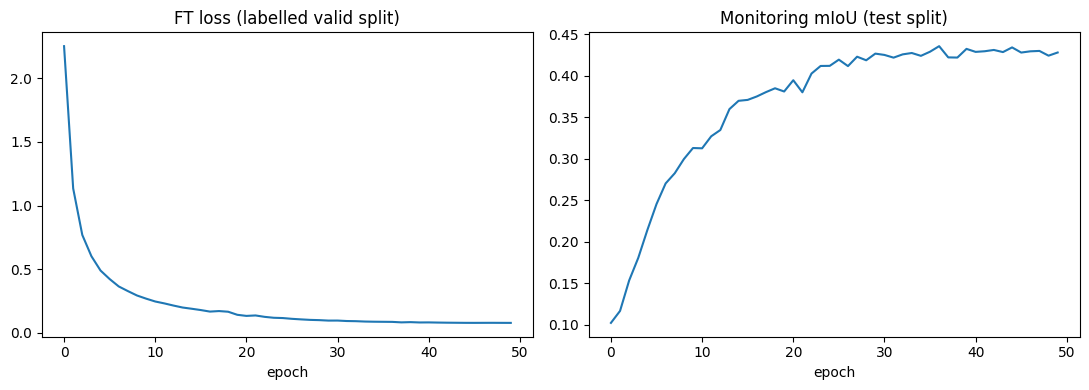

<All keys matched successfully>

In [18]:
freeze_final = (CONFIG["encoder_mode"] == "frozen")
model = DINOv2SegModel(pretrained_encoder, CONFIG["layer_taps"], CONFIG["patch_size"],
                        CONFIG["decoder_embed_dim"], CONFIG["num_classes"], freeze_final).to(DEVICE)

param_groups = [{"params": model.head.parameters(), "lr": CONFIG["ft_lr_decoder"]}]
if not freeze_final:
    param_groups.append({"params": model.backbone.parameters(), "lr": CONFIG["ft_lr_encoder"]})
optimizer_ft = torch.optim.AdamW(param_groups, weight_decay=CONFIG["ft_weight_decay"])
scheduler_ft = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_ft, T_max=CONFIG["ft_epochs"])
criterion = nn.CrossEntropyLoss()

def compute_miou(model, loader):
    model.eval()
    inter = torch.zeros(CONFIG["num_classes"]); union = torch.zeros(CONFIG["num_classes"])
    with torch.no_grad():
        for imgs, masks in loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            preds = model(imgs).argmax(1)
            for c in range(CONFIG["num_classes"]):
                p, g = (preds == c), (masks == c)
                inter[c] += (p & g).sum().item(); union[c] += (p | g).sum().item()
    return (inter / union.clamp(min=1)).mean().item()

train_loss_hist, monitor_miou_hist, ft_epoch_times = [], [], []
best_miou, best_state = -1, None

for epoch in range(CONFIG["ft_epochs"]):
    t0 = time.time()
    model.train()
    running = 0.0
    for imgs, masks in ft_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        logits = model(imgs)
        loss = criterion(logits, masks)
        optimizer_ft.zero_grad(); loss.backward(); optimizer_ft.step()
        running += loss.item()
    scheduler_ft.step()
    epoch_loss = running / len(ft_loader)
    monitor_miou = compute_miou(model, test_loader)   # test split double-role: monitoring here
    epoch_time = time.time() - t0

    train_loss_hist.append(epoch_loss); monitor_miou_hist.append(monitor_miou); ft_epoch_times.append(epoch_time)
    print(f"[FT] epoch {epoch+1}/{CONFIG['ft_epochs']} | train_loss={epoch_loss:.4f} | "
          f"monitor_mIoU(test)={monitor_miou:.4f} | {epoch_time:.1f}s")

    if monitor_miou > best_miou:
        best_miou, best_state = monitor_miou, copy.deepcopy(model.state_dict())

torch.save(best_state, f"{CONFIG['out_dir']}/dinov2_seg_best.pth")
print(f"Avg per-epoch FT time: {np.mean(ft_epoch_times):.1f}s | Best monitor mIoU: {best_miou:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11,4))
axes[0].plot(train_loss_hist); axes[0].set_title("FT loss (labelled valid split)"); axes[0].set_xlabel("epoch")
axes[1].plot(monitor_miou_hist); axes[1].set_title("Monitoring mIoU (test split)"); axes[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(f"{CONFIG['out_dir']}/dinov2_ft_curves.png", dpi=150); plt.show()

model.load_state_dict(best_state)

## Task E: final test metrics + label‑efficiency comparison

In [20]:
model.eval()
num_c = CONFIG["num_classes"]
inter = torch.zeros(num_c); union = torch.zeros(num_c); correct_c = torch.zeros(num_c); total_c = torch.zeros(num_c)
conf_mat = torch.zeros(num_c, num_c, dtype=torch.int64)
correct_px, total_px = 0, 0
dice_inter = torch.zeros(num_c); dice_sum = torch.zeros(num_c)

with torch.no_grad():
    for imgs, masks in test_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        preds = model(imgs).argmax(1)
        correct_px += (preds == masks).sum().item(); total_px += masks.numel()
        for c in range(num_c):
            p, g = (preds == c), (masks == c)
            inter[c] += (p & g).sum().item(); union[c] += (p | g).sum().item()
            dice_inter[c] += (p & g).sum().item(); dice_sum[c] += p.sum().item() + g.sum().item()
            correct_c[c] += (p & g).sum().item(); total_c[c] += g.sum().item()

        # --- vectorized confusion matrix update (replaces the slow per-pixel Python loop) ---
        t_flat = masks.flatten().cpu()
        p_flat = preds.flatten().cpu()
        idx = t_flat * num_c + p_flat
        conf_mat += torch.bincount(idx, minlength=num_c * num_c).reshape(num_c, num_c)

per_class_iou = (inter / union.clamp(min=1)).numpy()
per_class_dice = (2 * dice_inter / dice_sum.clamp(min=1)).numpy()
per_class_acc = (correct_c / total_c.clamp(min=1)).numpy()

test_mIoU = float(np.mean(per_class_iou))
pixel_acc = correct_px / total_px
mean_pixel_acc = float(np.mean(per_class_acc))

dinov2_summary = {
    "model": f"DINOv2-Seg ({CONFIG['hf_backbone']}, {CONFIG['encoder_mode']})",
    "test_mIoU": test_mIoU,
    "test_pixel_acc": pixel_acc,
    "test_mean_pixel_acc": mean_pixel_acc,
    "labelled_finetune_images": len(valid_imgs),
    "num_params_millions": sum(p.numel() for p in model.parameters()) / 1e6,
}
print(json.dumps(dinov2_summary, indent=2))

per_class_df = pd.DataFrame({
    "class_id": range(num_c), "class_name": CLASS_NAMES,
    "IoU": per_class_iou, "PixelAcc": per_class_acc, "Dice": per_class_dice,
})
per_class_df.to_csv(f"{CONFIG['out_dir']}/dinov2_test_metrics_per_class.csv", index=False)

# save confusion matrix too (useful for Task F / report figure)
conf_df = pd.DataFrame(conf_mat.numpy(), index=CLASS_NAMES, columns=CLASS_NAMES)
conf_df.to_csv(f"{CONFIG['out_dir']}/dinov2_confusion_matrix.csv")

# --- label-efficiency comparison vs Part-A baseline ---
PART_A_BASELINE = {"model": "SegFormer-B0 (Part-A, fully supervised)",
                    "test_mIoU": 0.4800178820641928, "train_images": len(train_imgs)}

comparison = pd.DataFrame([
    {"Model": PART_A_BASELINE["model"], "Test mIoU": PART_A_BASELINE["test_mIoU"],
     "Labelled images used": PART_A_BASELINE["train_images"]},
    {"Model": dinov2_summary["model"], "Test mIoU": dinov2_summary["test_mIoU"],
     "Labelled images used": len(valid_imgs)},
])
comparison["Label ratio vs Part-A"] = comparison["Labelled images used"] / PART_A_BASELINE["train_images"]
print(comparison.to_string(index=False))

{
  "model": "DINOv2-Seg (facebook/dinov2-small, finetune)",
  "test_mIoU": 0.4359097182750702,
  "test_pixel_acc": 0.9431217842299908,
  "test_mean_pixel_acc": 0.5237910747528076,
  "labelled_finetune_images": 697,
  "num_params_millions": 22.730948
}
                                       Model  Test mIoU  Labelled images used  Label ratio vs Part-A
     SegFormer-B0 (Part-A, fully supervised)   0.480018                  2473               1.000000
DINOv2-Seg (facebook/dinov2-small, finetune)   0.435910                   697               0.281844


## Task F: error analysis (worst‑K predictions)

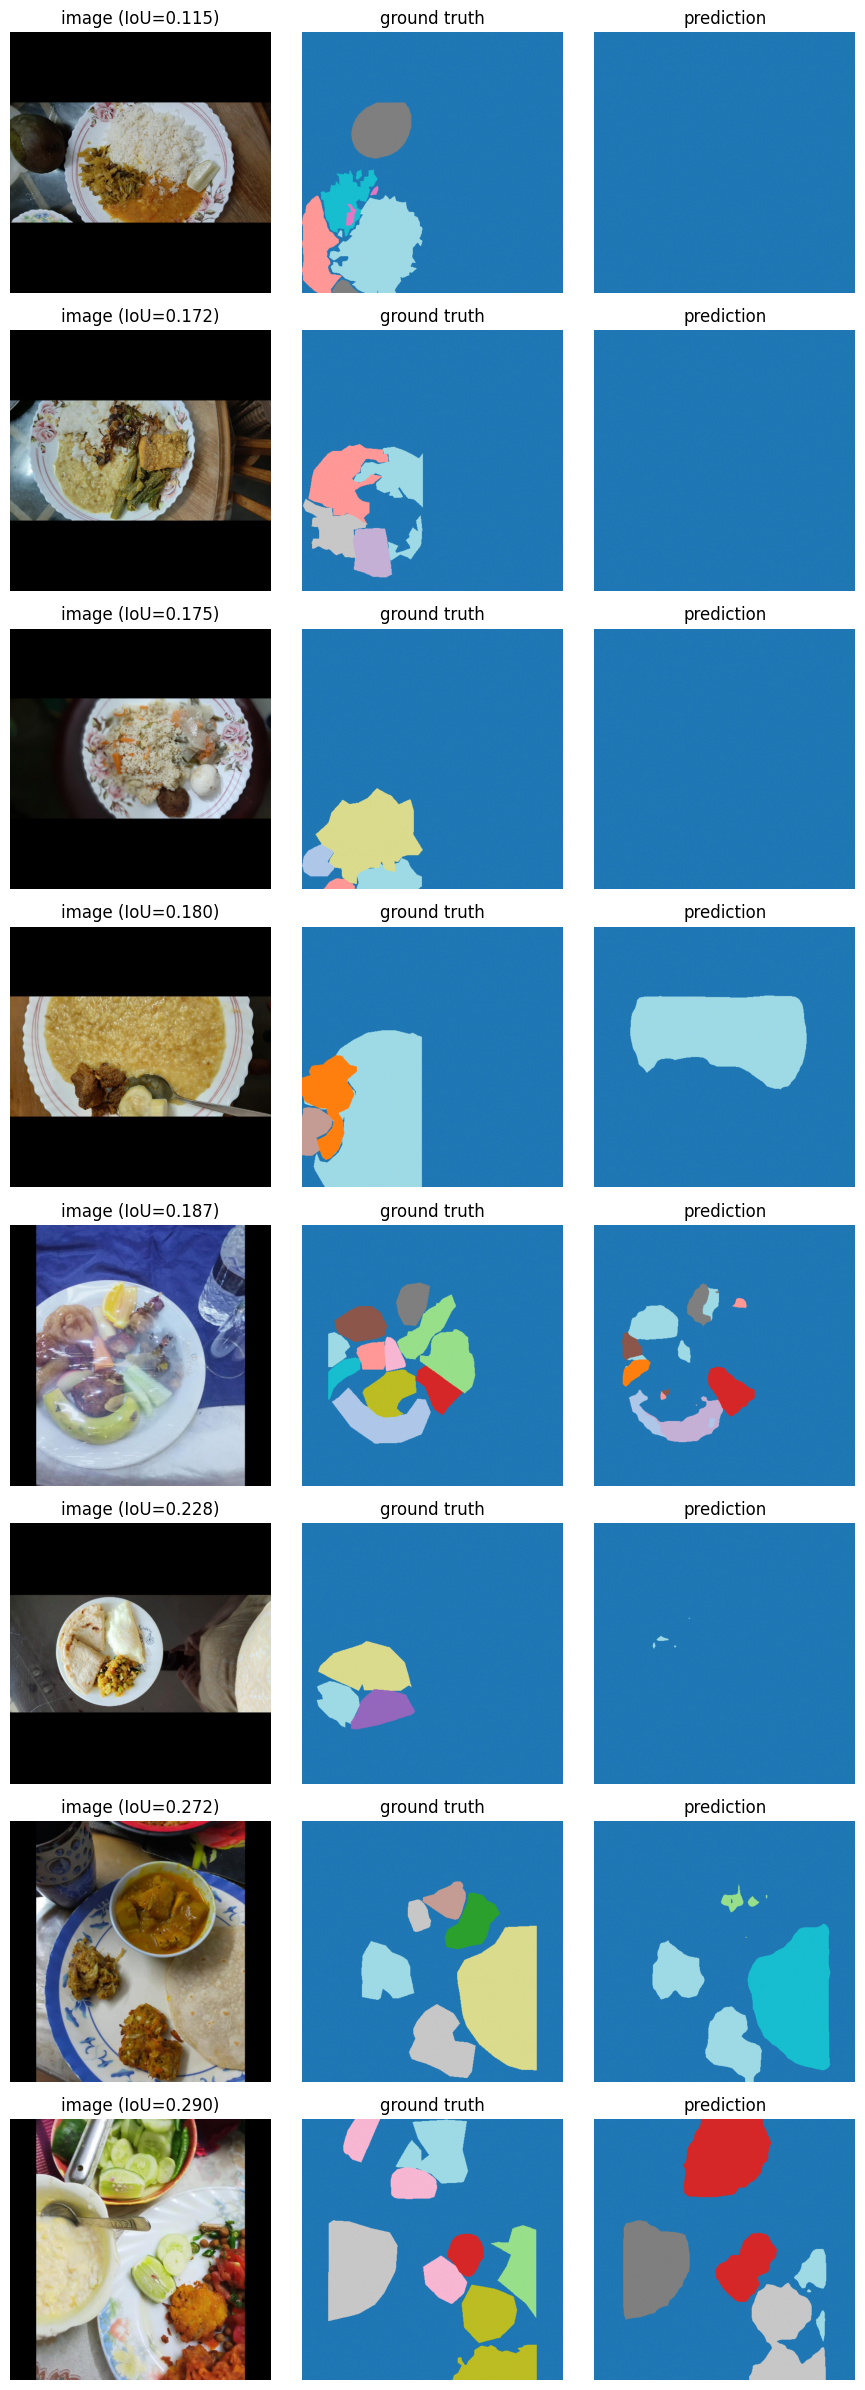

In [21]:
def per_image_miou(model, loader, k=8):
    model.eval()
    scores = []
    with torch.no_grad():
        for bi, (imgs, masks) in enumerate(loader):
            imgs_d, masks_d = imgs.to(DEVICE), masks.to(DEVICE)
            preds = model(imgs_d).argmax(1)
            for i in range(imgs.shape[0]):
                p, g = preds[i], masks_d[i]
                ious = []
                for c in torch.unique(g).tolist():
                    pc, gc = (p == c), (g == c)
                    u = (pc | gc).sum().item()
                    if u > 0:
                        ious.append((pc & gc).sum().item() / u)
                scores.append((np.mean(ious), bi, i, imgs[i].cpu(), masks[i].cpu(), p.cpu()))
    scores.sort(key=lambda x: x[0])
    return scores[:k]

worst = per_image_miou(model, test_loader, k=8)
fig, axes = plt.subplots(len(worst), 3, figsize=(9, 3*len(worst)))
for row, (score, bi, i, img, gt, pred) in enumerate(worst):
    axes[row,0].imshow(denorm(img)); axes[row,0].set_title(f"image (IoU={score:.3f})"); axes[row,0].axis("off")
    axes[row,1].imshow(gt, cmap="tab20"); axes[row,1].set_title("ground truth"); axes[row,1].axis("off")
    axes[row,2].imshow(pred, cmap="tab20"); axes[row,2].set_title("prediction"); axes[row,2].axis("off")
plt.tight_layout(); plt.savefig(f"{CONFIG['out_dir']}/dinov2_worst_predictions.png", dpi=150); plt.show()

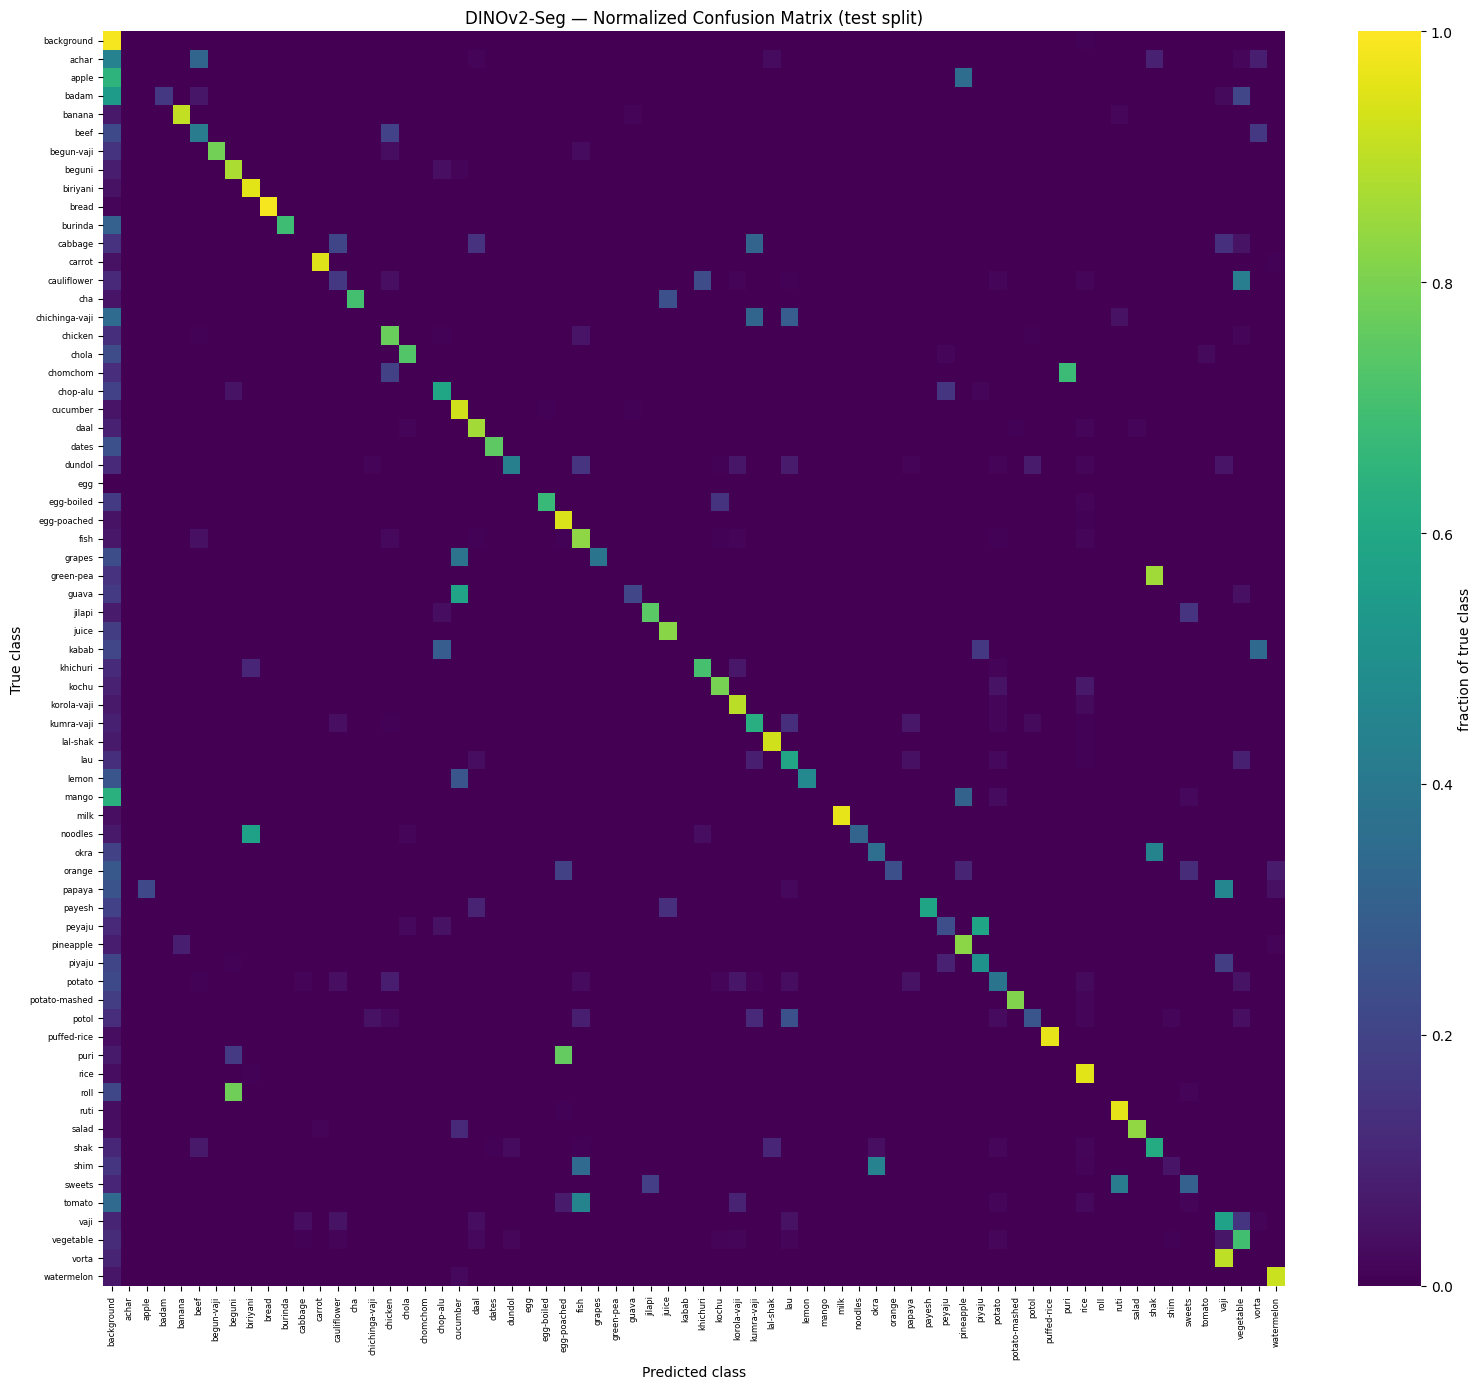

 true_class predicted_as  pixel_count  fraction_of_true_class
      vorta         vaji         8091                0.899200
  green-pea         shak         7070                0.855518
       roll       beguni         4685                0.778239
       puri  egg-poached        99832                0.759878
   chomchom         puri        23723                0.683050
      apple   background         2238                0.648132
      mango   background        21569                0.634121
     peyaju       piyaju        96142                0.584770
      guava     cucumber        55636                0.581960
    noodles     biriyani       101310                0.567722
      badam   background        25708                0.549575
     papaya         vaji         8913                0.458960
       okra         shak        19735                0.449145
     tomato         fish        25232                0.447027
      achar   background        42338                0.444975
       s

In [23]:
import seaborn as sns

# --- normalize confusion matrix by row (true class) so each row sums to 1 ---
conf_np = conf_mat.numpy().astype(np.float64)
row_sums = conf_np.sum(axis=1, keepdims=True)
conf_norm = np.divide(conf_np, row_sums, out=np.zeros_like(conf_np), where=row_sums != 0)

# --- full heatmap (68x68 -- readable at this size, but small font) ---
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(conf_norm, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cmap="viridis", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "fraction of true class"})
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_title("DINOv2-Seg — Normalized Confusion Matrix (test split)")
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.savefig(f"{CONFIG['out_dir']}/dinov2_confusion_matrix_heatmap.png", dpi=200)
plt.show()

# --- top-20 off-diagonal confusions (the pairs actually worth discussing in Task F) ---
off_diag = []
for i in range(num_c):
    for j in range(num_c):
        if i != j and conf_mat[i, j] > 0:
            off_diag.append((CLASS_NAMES[i], CLASS_NAMES[j], int(conf_mat[i, j]), conf_norm[i, j]))

confusion_df = pd.DataFrame(off_diag, columns=["true_class", "predicted_as", "pixel_count", "fraction_of_true_class"])
confusion_df = confusion_df.sort_values("fraction_of_true_class", ascending=False).head(20)
confusion_df.to_csv(f"{CONFIG['out_dir']}/dinov2_top_confusions.csv", index=False)
print(confusion_df.to_string(index=False))

## Append to shared results.json (for the Final Comparison notebook)

In [24]:
results_path = f"{CONFIG['out_dir']}/results.json"
all_results = {}
if os.path.exists(results_path):
    all_results = json.load(open(results_path))
all_results["dinov2"] = {**dinov2_summary,
                          "frozen_probe_miou": miou_frozen, "finetuned_probe_miou": miou_finetune,
                          "chosen_strategy": CONFIG["encoder_mode"],
                          "ssl_avg_epoch_time_s": float(np.mean(ssl_epoch_times)),
                          "ft_avg_epoch_time_s": float(np.mean(ft_epoch_times))}
json.dump(all_results, open(results_path, "w"), indent=2)
print("Saved:", results_path)

Saved: /kaggle/working/dinov2_outputs/results.json
